In [14]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
import os

DATA_DIR = '/content/drive/MyDrive/data'  # ⚠️ 본인 폴더로 바꾸세요
print(os.listdir(DATA_DIR))

['test.csv', 'sample_submission.csv', 'train.csv']


In [16]:
import pandas as pd

train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("\n--- Train 처음 5줄 ---")
train.head()

Train shape: (21693, 54)
Test shape: (15004, 53)

--- Train 처음 5줄 ---


,ID,X_01,X_02,X_03,X_04,X_05,X_06,X_07,X_08,X_09,...,X_44,X_45,X_46,X_47,X_48,X_49,X_50,X_51,X_52,target
0,TRAIN_00000,0.016,0.242994,0.538536,0.522295,0.374494,0.555348,0.639091,0.494800,0.584233,...,0.435885,0.555359,0.751714,0.376801,0.466993,0.527585,0.598101,0.312160,0.582797,0
1,TRAIN_00001,0.019,0.240380,0.517223,0.538976,0.371149,0.693825,0.663667,0.530931,0.577200,...,0.479859,0.693855,0.748955,0.356118,0.613461,0.508069,0.569814,0.313351,0.570513,20
2,TRAIN_00002,0.012,0.248946,0.547109,0.466713,0.415830,0.656887,0.681782,0.580773,0.527069,...,0.416115,0.656884,0.750059,0.417200,0.525393,0.551947,0.639860,0.342627,0.573139,1
3,TRAIN_00003,0.013,0.245877,0.527870,0.515534,0.379199,0.594391,0.663816,0.494931,0.581796,...,0.436761,0.594364,0.746297,0.374659,0.694290,0.532705,0.581142,0.316417,0.562656,19
4,TRAIN_00004,0.024,0.239237,0.566087,0.514384,0.378451,0.610543,0.644811,0.508567,0.593614,...,0.422407,0.610526,0.749565,0.372742,0.565549,0.535573,0.580484,0.314982,0.591692,15


클래스별 개수:
target
0     1033
1     1033
2     1033
3     1033
4     1033
5     1033
6     1033
7     1033
8     1033
9     1033
10    1033
11    1033
12    1033
13    1033
14    1033
15    1033
16    1033
17    1033
18    1033
19    1033
20    1033
Name: count, dtype: int64

총 클래스 수: 21
가장 많은 클래스: 0 (1033개)
가장 적은 클래스: 0 (1033개)
불균형 비율 (max/min): 1.00배


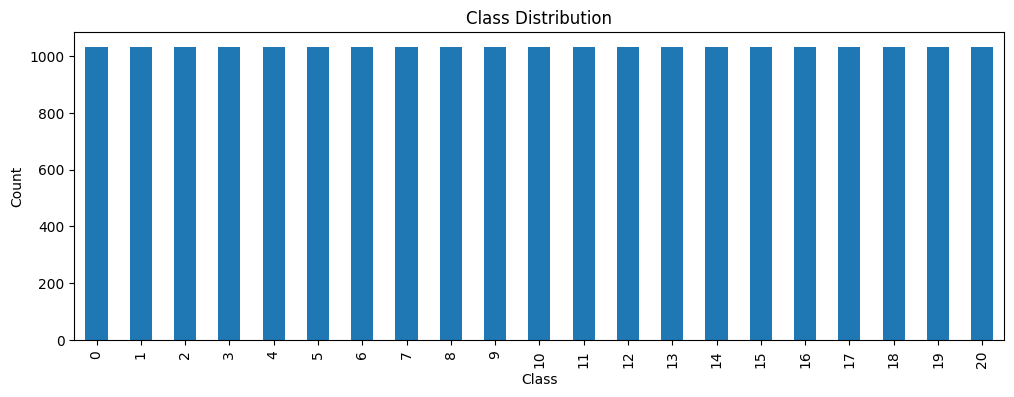

In [17]:
import matplotlib.pyplot as plt

target_counts = train['target'].value_counts().sort_index()
print("클래스별 개수:")
print(target_counts)

print(f"\n총 클래스 수: {train['target'].nunique()}")
print(f"가장 많은 클래스: {target_counts.idxmax()} ({target_counts.max()}개)")
print(f"가장 적은 클래스: {target_counts.idxmin()} ({target_counts.min()}개)")
print(f"불균형 비율 (max/min): {target_counts.max() / target_counts.min():.2f}배")

plt.figure(figsize=(12, 4))
target_counts.plot(kind='bar')
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

In [18]:
# ② 결측치
print("=== 결측치 ===")
print(f"Train: {train.isnull().sum().sum()}개")
print(f"Test:  {test.isnull().sum().sum()}개")

# ④ 데이터 타입
print("\n=== 데이터 타입 ===")
print(train.dtypes.value_counts())

# ③ X 값 통계 (요약)
print("\n=== X 값 통계 (요약) ===")
desc = train.iloc[:, 1:-1].describe().T  # 전치해서 보기 편하게
print(desc[['min', 'mean', 'max', 'std']].head(10))  # 처음 10개만
print("...")
print(desc[['min', 'mean', 'max', 'std']].tail(10))  # 마지막 10개만

=== 결측치 ===
Train: 0개
Test:  0개

=== 데이터 타입 ===
float64    52
object      1
int64       1
Name: count, dtype: int64

=== X 값 통계 (요약) ===
        min      mean    max       std
X_01 -0.003  0.017989  0.037  0.004794
X_02  0.000  0.258061  1.000  0.064098
X_03  0.000  0.533411  1.000  0.057962
X_04  0.000  0.510776  1.000  0.082500
X_05  0.000  0.421508  1.000  0.168995
X_06  0.000  0.600059  1.000  0.082645
X_07  0.000  0.618569  1.000  0.139561
X_08  0.000  0.534465  1.000  0.153934
X_09  0.000  0.550514  1.000  0.134451
X_10  0.000  0.517199  1.000  0.092376
...
      min      mean  max       std
X_43  0.0  0.266428  1.0  0.090812
X_44  0.0  0.453256  1.0  0.072222
X_45  0.0  0.600050  1.0  0.082649
X_46  0.0  0.731735  1.0  0.085227
X_47  0.0  0.408285  1.0  0.137385
X_48  0.0  0.477403  1.0  0.072804
X_49  0.0  0.520059  1.0  0.099855
X_50  0.0  0.582188  1.0  0.065809
X_51  0.0  0.359334  1.0  0.163723
X_52  0.0  0.571657  1.0  0.070578


In [19]:
print("=== Train vs Test 평균 비교 ===\n")

train_x = train.drop(columns=['ID', 'target'])
test_x = test.drop(columns=['ID'])

# 각 센서별 평균 비교
comparison = pd.DataFrame({
    'train_mean': train_x.mean(),
    'test_mean': test_x.mean(),
    'train_std': train_x.std(),
    'test_std': test_x.std(),
})
comparison['mean_diff'] = (comparison['train_mean'] - comparison['test_mean']).abs()
comparison['std_diff'] = (comparison['train_std'] - comparison['test_std']).abs()

# 차이 큰 센서 Top 5
print("평균 차이가 큰 센서 Top 5:")
print(comparison.nlargest(5, 'mean_diff')[['train_mean', 'test_mean', 'mean_diff']])

print("\n표준편차 차이가 큰 센서 Top 5:")
print(comparison.nlargest(5, 'std_diff')[['train_std', 'test_std', 'std_diff']])

=== Train vs Test 평균 비교 ===

평균 차이가 큰 센서 Top 5:
      train_mean  test_mean  mean_diff
X_37   23.399720  22.207690   1.192030
X_19   50.956294  51.709624   0.753330
X_40   42.253450  41.797026   0.456424
X_11   18.918073  18.666815   0.251258
X_12    0.508895   0.526803   0.017908

표준편차 차이가 큰 센서 Top 5:
      train_std   test_std  std_diff
X_37  12.815777   7.303229  5.512548
X_40  11.540643   6.418837  5.121806
X_11   5.059086   2.480499  2.578587
X_19  17.774983  16.985880  0.789103
X_43   0.090812   0.025697  0.065115


In [20]:
class_means = train.groupby('target').mean(numeric_only=True)
class_variation = class_means.std()

print("클래스 구분 잘 되는 센서 Top 10:")
print(class_variation.nlargest(10))

print("\n클래스 구분 안 되는 센서 Top 5:")
print(class_variation.nsmallest(5))

클래스 구분 잘 되는 센서 Top 10:
X_19    13.347586
X_37     3.976141
X_40     3.347643
X_11     2.747494
X_28     0.196066
X_51     0.151002
X_16     0.148852
X_05     0.145539
X_33     0.138268
X_07     0.137808
dtype: float64

클래스 구분 안 되는 센서 Top 5:
X_01    0.001275
X_34    0.003832
X_48    0.008005
X_03    0.013749
X_23    0.026490
dtype: float64


In [21]:
import numpy as np
import pandas as pd

def feature_engineering(df):
    """EDA 결과 반영한 피처 엔지니어링"""
    df = df.copy()

    # ID, target 제외한 센서 컬럼들
    sensors = [c for c in df.columns if c.startswith('X_')]

    # ============================================
    # 1. 행 단위 기본 통계 피처 (전체 센서)
    # ============================================
    df['row_mean']  = df[sensors].mean(axis=1)
    df['row_std']   = df[sensors].std(axis=1)
    df['row_min']   = df[sensors].min(axis=1)
    df['row_max']   = df[sensors].max(axis=1)
    df['row_range'] = df['row_max'] - df['row_min']
    df['row_skew']  = df[sensors].skew(axis=1)
    df['row_median']= df[sensors].median(axis=1)

    # ============================================
    # 2. 핵심 센서 기반 피처 (EDA 발견)
    # ============================================
    core_sensors = ['X_19', 'X_37', 'X_40', 'X_11']

    # 핵심 센서 통계
    df['core_mean'] = df[core_sensors].mean(axis=1)
    df['core_std']  = df[core_sensors].std(axis=1)
    df['core_max']  = df[core_sensors].max(axis=1)
    df['core_min']  = df[core_sensors].min(axis=1)

    # 핵심 센서 페어 조합
    df['X19_X37_ratio'] = df['X_19'] / (df['X_37'] + 1e-6)
    df['X19_X40_ratio'] = df['X_19'] / (df['X_40'] + 1e-6)
    df['X19_X11_ratio'] = df['X_19'] / (df['X_11'] + 1e-6)
    df['X19_X37_diff']  = df['X_19'] - df['X_37']
    df['X19_X40_diff']  = df['X_19'] - df['X_40']
    df['X37_X40_diff']  = df['X_37'] - df['X_40']

    return df

# 적용
train_fe = feature_engineering(train)
test_fe = feature_engineering(test)

print(f"원래 컬럼 수: {len(train.columns)}")
print(f"FE 후 컬럼 수: {len(train_fe.columns)}")
print(f"추가된 피처: {len(train_fe.columns) - len(train.columns)}개")
print(f"\n새 피처 목록:")
new_features = [c for c in train_fe.columns if c not in train.columns]
print(new_features)

원래 컬럼 수: 54
FE 후 컬럼 수: 71
추가된 피처: 17개

새 피처 목록:
['row_mean', 'row_std', 'row_min', 'row_max', 'row_range', 'row_skew', 'row_median', 'core_mean', 'core_std', 'core_max', 'core_min', 'X19_X37_ratio', 'X19_X40_ratio', 'X19_X11_ratio', 'X19_X37_diff', 'X19_X40_diff', 'X37_X40_diff']


In [22]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
import numpy as np

# ============================================
# 실험 1: 원본 피처만 (베이스라인)
# ============================================
print("=" * 60)
print("실험 1: 원본 피처만 (52개)")
print("=" * 60)

X_orig = train.drop(columns=['ID', 'target']).values
y = train['target'].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores_orig = []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_orig, y)):
    X_tr, X_val = X_orig[tr_idx], X_orig[val_idx]
    y_tr, y_val = y[tr_idx], y[val_idx]

    model = lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=63,
        random_state=42,
        verbose=-1
    )
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)],
              callbacks=[lgb.early_stopping(50, verbose=False)])

    preds = model.predict(X_val)
    f1 = f1_score(y_val, preds, average='macro')
    scores_orig.append(f1)
    print(f"Fold {fold}: Macro-F1 = {f1:.4f}")

print(f"\n원본 피처 평균 Macro-F1: {np.mean(scores_orig):.4f}")

# ============================================
# 실험 2: FE 피처 추가 (69개 = 52 + 17)
# ============================================
print("\n" + "=" * 60)
print("실험 2: FE 피처 추가 (69개)")
print("=" * 60)

X_fe = train_fe.drop(columns=['ID', 'target']).values

scores_fe = []
last_model = None  # 마지막 fold 모델 저장 (importance용)

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_fe, y)):
    X_tr, X_val = X_fe[tr_idx], X_fe[val_idx]
    y_tr, y_val = y[tr_idx], y[val_idx]

    model = lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=63,
        random_state=42,
        verbose=-1
    )
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)],
              callbacks=[lgb.early_stopping(50, verbose=False)])

    preds = model.predict(X_val)
    f1 = f1_score(y_val, preds, average='macro')
    scores_fe.append(f1)
    print(f"Fold {fold}: Macro-F1 = {f1:.4f}")
    last_model = model

print(f"\nFE 피처 평균 Macro-F1: {np.mean(scores_fe):.4f}")

# ============================================
# 결과 비교
# ============================================
print("\n" + "=" * 60)
print("📊 결과 비교")
print("=" * 60)
diff = np.mean(scores_fe) - np.mean(scores_orig)
print(f"원본:    {np.mean(scores_orig):.4f}")
print(f"FE 추가: {np.mean(scores_fe):.4f}")
print(f"차이:    {diff:+.4f} ({'↑' if diff > 0 else '↓'})")

# ============================================
# Feature Importance (FE 모델 기준)
# ============================================
print("\n" + "=" * 60)
print("🏆 Feature Importance Top 20")
print("=" * 60)
feature_names = train_fe.drop(columns=['ID', 'target']).columns
importance = pd.DataFrame({
    'feature': feature_names,
    'importance': last_model.feature_importances_
}).sort_values('importance', ascending=False)

print(importance.head(20))

실험 1: 원본 피처만 (52개)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 0: Macro-F1 = 0.8054


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 1: Macro-F1 = 0.8029


...

Fold 2: Macro-F1 = 0.8033


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 3: Macro-F1 = 0.8025


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 4: Macro-F1 = 0.8041

FE 피처 평균 Macro-F1: 0.8045

📊 결과 비교
원본:    0.8023
FE 추가: 0.8045
차이:    +0.0022 (↑)

🏆 Feature Importance Top 20
         feature  importance
39          X_40        7650
33          X_34        6195
68  X37_X40_diff        5290
45          X_46        5020
28          X_29        4283
13          X_14        3444
47          X_48        3303
7           X_08        3289
40          X_41        3222
35          X_36        3049
26          X_27        2903
10          X_11        2462
49          X_50        2417
6           X_07        2352
36          X_37        2347
48          X_49        2341
34          X_35        2219
32          X_33        2192
21          X_22        2139
1           X_02        2100


In [23]:
import torch
print("GPU 사용 가능?", torch.cuda.is_available())

GPU 사용 가능? True


In [24]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
from scipy.optimize import linear_sum_assignment
import numpy as np
import pandas as pd

# ============================================
# 후처리 함수들 (6등 코드에서 가져옴)
# ============================================
def compute_quota(probs):
    N, C = probs.shape
    base = N // C
    rem = N % C
    quota = np.full(C, base, int)
    strength = probs.mean(0)
    order = np.argsort(-strength)
    quota[order[:rem]] += 1
    return quota

def balanced_assign_hungarian(probs, quota):
    eps = 1e-15
    N, C = probs.shape
    cols = []
    col_to_class = []
    for c in range(C):
        q = int(quota[c])
        cost_c = -np.log(probs[:, c] + eps)
        cols.append(np.repeat(cost_c[:, None], q, axis=1))
        col_to_class.extend([c] * q)
    cost = np.concatenate(cols, axis=1)
    row_ind, col_ind = linear_sum_assignment(cost)
    pred = np.zeros(N, int)
    pred[row_ind] = np.array(col_to_class)[col_ind]
    return pred

# ============================================
# LightGBM으로 OOF 확률 만들기 (FE 적용)
# ============================================
print("=" * 60)
print("🧪 LightGBM 학습 (OOF 확률 생성)")
print("=" * 60)

X = train_fe.drop(columns=['ID', 'target']).values
y = train['target'].values
NUM_CLASSES = 21

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = np.zeros((len(X), NUM_CLASSES))  # OOF 확률 저장용

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, X_val = X[tr_idx], X[val_idx]
    y_tr, y_val = y[tr_idx], y[val_idx]

    model = lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=63,
        random_state=42,
        verbose=-1,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)],
              callbacks=[lgb.early_stopping(50, verbose=False)])

    # 확률 예측 (argmax용 + Hungarian용)
    oof_probs[val_idx] = model.predict_proba(X_val)
    print(f"  Fold {fold} 완료")

print("\n✅ OOF 확률 생성 완료")

# ============================================
# 비교 1: 단순 Argmax (후처리 X)
# ============================================
print("\n" + "=" * 60)
print("🔬 후처리 방식 비교")
print("=" * 60)

preds_argmax = oof_probs.argmax(axis=1)
f1_argmax = f1_score(y, preds_argmax, average='macro')
print(f"방식 A (Argmax):    Macro-F1 = {f1_argmax:.4f}")

# ============================================
# 비교 2: Hungarian 후처리
# ============================================
quota = compute_quota(oof_probs)
preds_hungarian = balanced_assign_hungarian(oof_probs, quota)
f1_hungarian = f1_score(y, preds_hungarian, average='macro')
print(f"방식 B (Hungarian): Macro-F1 = {f1_hungarian:.4f}")

# ============================================
# 결과 분석
# ============================================
print("\n" + "=" * 60)
print("📊 최종 결과")
print("=" * 60)
diff = f1_hungarian - f1_argmax
print(f"Argmax:     {f1_argmax:.4f}")
print(f"Hungarian:  {f1_hungarian:.4f}")
print(f"차이:       {diff:+.4f}")

if diff > 0.005:
    print("✅ Hungarian이 효과적! (베이스라인 가정 검증됨)")
elif abs(diff) <= 0.005:
    print("⚠️ 차이 거의 없음. 단순한 argmax로 충분할 수도.")
else:
    print("🚨 Argmax가 더 좋음! Hungarian 후처리 제거 권장!")

# ============================================
# 클래스별 예측 분포 비교
# ============================================
print("\n" + "=" * 60)
print("📊 클래스별 예측 분포")
print("=" * 60)
print(f"{'클래스':>6} {'실제':>6} {'Argmax':>8} {'Hungarian':>10}")
true_counts = pd.Series(y).value_counts().sort_index()
argmax_counts = pd.Series(preds_argmax).value_counts().sort_index()
hungarian_counts = pd.Series(preds_hungarian).value_counts().sort_index()

for c in range(NUM_CLASSES):
    print(f"{c:>6} {true_counts.get(c, 0):>6} "
          f"{argmax_counts.get(c, 0):>8} {hungarian_counts.get(c, 0):>10}")

🧪 LightGBM 학습 (OOF 확률 생성)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Fold 0 완료


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Fold 1 완료


...

  Fold 2 완료


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Fold 3 완료


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Fold 4 완료

✅ OOF 확률 생성 완료

🔬 후처리 방식 비교
방식 A (Argmax):    Macro-F1 = 0.8046
방식 B (Hungarian): Macro-F1 = 0.8006

📊 최종 결과
Argmax:     0.8046
Hungarian:  0.8006
차이:       -0.0040
⚠️ 차이 거의 없음. 단순한 argmax로 충분할 수도.

📊 클래스별 예측 분포
   클래스     실제   Argmax  Hungarian
     0   1033     1177       1033
     1   1033     1035       1033
     2   1033     1033       1033
     3   1033     1194       1033
     4   1033     1045       1033
     5   1033     1034       1033
     6   1033     1033       1033
     7   1033     1034       1033
     8   1033      998       1033
     9   1033     1219       1033
    10   1033     1058       1033
    11   1033      905       1033
    12   1033     1054       1033
    13   1033      987       1033
    14   1033      991       1033
    15   1033     1127       1033
    16   1033      801       1033
    17   1033     1033       1033
    18   1033     1041       1033
    19   1033      868       1033
    20   1033     1026       1033


In [25]:
import numpy as np
import pandas as pd

def feature_engineering_v2(df):
    """FE 2차: Importance 기반 조합 피처 집중"""
    df = df.copy()

    # ============================================
    # Importance Top 10 센서 (1차 실험 결과)
    # ============================================
    top_sensors = ['X_40', 'X_34', 'X_46', 'X_29', 'X_14',
                   'X_48', 'X_08', 'X_41', 'X_36', 'X_27']

    # ============================================
    # 1. Top 센서 페어 차이 (Top 5끼리만)
    # ============================================
    top5 = ['X_40', 'X_34', 'X_46', 'X_29', 'X_14']
    for i, a in enumerate(top5):
        for b in top5[i+1:]:
            df[f'{a}_{b}_diff'] = df[a] - df[b]

    # ============================================
    # 2. Top 센서 페어 비율 (Top 5끼리)
    # ============================================
    for i, a in enumerate(top5):
        for b in top5[i+1:]:
            df[f'{a}_{b}_ratio'] = df[a] / (df[b] + 1e-6)

    # ============================================
    # 3. Top 센서 페어 곱 (Top 5끼리)
    # ============================================
    for i, a in enumerate(top5):
        for b in top5[i+1:]:
            df[f'{a}_{b}_mul'] = df[a] * df[b]

    # ============================================
    # 4. Top 10 센서 통계
    # ============================================
    df['top_mean'] = df[top_sensors].mean(axis=1)
    df['top_std']  = df[top_sensors].std(axis=1)
    df['top_max']  = df[top_sensors].max(axis=1)
    df['top_min']  = df[top_sensors].min(axis=1)

    # ============================================
    # 5. 비선형 변환 (Importance 상위 큰 값 센서)
    # ============================================
    large_sensors = ['X_40', 'X_34', 'X_11', 'X_37', 'X_19']
    for s in large_sensors:
        df[f'{s}_log'] = np.log1p(np.abs(df[s]))
        df[f'{s}_sqrt'] = np.sqrt(np.abs(df[s]))

    # ============================================
    # 6. EDA에서 발견한 핵심 4개 센서 조합 (1차에서 효과 있던 거 유지)
    # ============================================
    df['X37_X40_diff'] = df['X_37'] - df['X_40']  # 1차에서 3위였음!

    return df


# ============================================
# 실험 실행
# ============================================
print("=" * 60)
print("🧪 FE 2차 실험")
print("=" * 60)

# FE 2차 적용
train_fe2 = feature_engineering_v2(train)
test_fe2 = feature_engineering_v2(test)

print(f"원본 컬럼 수: {len(train.columns)}")
print(f"FE 2차 컬럼 수: {len(train_fe2.columns)}")
print(f"추가된 피처: {len(train_fe2.columns) - len(train.columns)}개")

🧪 FE 2차 실험
원본 컬럼 수: 54
FE 2차 컬럼 수: 99
추가된 피처: 45개


In [27]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

# ============================================
# 3개 비교: 원본 / FE 1차 / FE 2차
# ============================================
def evaluate_lgbm(X, y, name):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = []
    last_model = None
    for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y)):
        X_tr, X_val = X[tr_idx], X[val_idx]
        y_tr, y_val = y[tr_idx], y[val_idx]
        model = lgb.LGBMClassifier(
            n_estimators=500, learning_rate=0.05, num_leaves=63,
            random_state=42, verbose=-1, n_jobs=-1
        )
        model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)],
                  callbacks=[lgb.early_stopping(50, verbose=False)])
        preds = model.predict(X_val)
        scores.append(f1_score(y_val, preds, average='macro'))
        last_model = model
    mean_score = np.mean(scores)
    print(f"  {name}: {mean_score:.4f}")
    return mean_score, last_model

y = train['target'].values

print("\n📊 LightGBM Macro-F1 비교")
print("-" * 60)

# 원본 (참고용)
X_orig = train.drop(columns=['ID', 'target']).values
score_orig, _ = evaluate_lgbm(X_orig, y, "원본 (52개)")

# FE 1차
train_fe1 = feature_engineering(train)  # 1차 함수 그대로
X_fe1 = train_fe1.drop(columns=['ID', 'target']).values
score_fe1, _ = evaluate_lgbm(X_fe1, y, f"FE 1차 ({X_fe1.shape[1]}개)")

# FE 2차
X_fe2 = train_fe2.drop(columns=['ID', 'target']).values
score_fe2, model_fe2 = evaluate_lgbm(X_fe2, y, f"FE 2차 ({X_fe2.shape[1]}개)")

# 결과
print("-" * 60)
print(f"📊 개선폭")
print(f"  FE 1차: {score_fe1 - score_orig:+.4f}")
print(f"  FE 2차: {score_fe2 - score_orig:+.4f}")
print(f"  2차 - 1차: {score_fe2 - score_fe1:+.4f}")

# Top 20 Importance (FE 2차 모델)
print("\n🏆 FE 2차 Feature Importance Top 20")
print("-" * 60)
feature_names = train_fe2.drop(columns=['ID', 'target']).columns
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': model_fe2.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)
print(importance_df.head(20).to_string(index=False))

# 새 피처들 중 Top 진입 개수
new_features = [c for c in train_fe2.columns
                if c not in train.columns and c not in train_fe1.columns]
top20_features = set(importance_df.head(20)['feature'])
new_in_top20 = [f for f in new_features if f in top20_features]
print(f"\n🆕 FE 2차에서 새로 만든 피처 중 Top 20 진입: {len(new_in_top20)}개")
for f in new_in_top20:
    rank = importance_df[importance_df['feature']==f].index[0] + 1
    print(f"  {rank}위: {f}")


📊 LightGBM Macro-F1 비교
------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  원본 (52개): 0.8023


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  FE 1차 (69개): 0.8045


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  FE 2차 (97개): 0.8043
------------------------------------------------------------
📊 개선폭
  FE 1차: +0.0022
  FE 2차: +0.0020
  2차 - 1차: -0.0002

🏆 FE 2차 Feature Importance Top 20
------------------------------------------------------------
        feature  importance
  X_40_X_46_mul        4456
   X37_X40_diff        4276
           X_48        3217
           X_08        3026
           X_11        2932
           X_36        2761
           X_41        2748
           X_27        2696
        top_min        2264
X_29_X_14_ratio        2189
           X_07        2061
           X_35        2020
           X_37        2018
           X_19        1992
           X_33        1961
 X_40_X_29_diff        1957
           X_50        1839
           X_09        1801
           X_02        1784
           X_49        1770

🆕 FE 2차에서 새로 만든 피처 중 Top 20 진입: 4개
  16위: X_40_X_29_diff
  10위: X_29_X_14_ratio
  1위: X_40_X_46_mul
  9위: top_min


In [28]:
def feature_engineering_v15(df):
    """FE 1.5차: 1차 + 검증된 효과적 새 피처 4개"""
    df = df.copy()
    sensors = [c for c in df.columns if c.startswith('X_')]

    # ============================================
    # 1차 피처 유지 (행 통계 + 핵심 센서 조합)
    # ============================================
    df['row_mean']   = df[sensors].mean(axis=1)
    df['row_std']    = df[sensors].std(axis=1)
    df['row_min']    = df[sensors].min(axis=1)
    df['row_max']    = df[sensors].max(axis=1)
    df['row_range']  = df['row_max'] - df['row_min']
    df['row_skew']   = df[sensors].skew(axis=1)
    df['row_median'] = df[sensors].median(axis=1)

    core_sensors = ['X_19', 'X_37', 'X_40', 'X_11']
    df['core_mean'] = df[core_sensors].mean(axis=1)
    df['core_std']  = df[core_sensors].std(axis=1)
    df['core_max']  = df[core_sensors].max(axis=1)
    df['core_min']  = df[core_sensors].min(axis=1)

    df['X19_X37_ratio'] = df['X_19'] / (df['X_37'] + 1e-6)
    df['X19_X40_ratio'] = df['X_19'] / (df['X_40'] + 1e-6)
    df['X19_X11_ratio'] = df['X_19'] / (df['X_11'] + 1e-6)
    df['X19_X37_diff']  = df['X_19'] - df['X_37']
    df['X19_X40_diff']  = df['X_19'] - df['X_40']
    df['X37_X40_diff']  = df['X_37'] - df['X_40']

    # ============================================
    # ⭐ 2차에서 검증된 효과적 피처만 추가 (Top 진입한 것들)
    # ============================================
    df['X_40_X_46_mul']    = df['X_40'] * df['X_46']           # 2차 importance 1위
    df['X_29_X_14_ratio']  = df['X_29'] / (df['X_14'] + 1e-6)  # 2차 10위
    df['X_40_X_29_diff']   = df['X_40'] - df['X_29']           # 2차 16위

    # top_min은 top_sensors 정의 필요
    top_sensors = ['X_40', 'X_34', 'X_46', 'X_29', 'X_14',
                   'X_48', 'X_08', 'X_41', 'X_36', 'X_27']
    df['top_min'] = df[top_sensors].min(axis=1)  # 2차 9위

    return df


# 비교 실험
print("=" * 60)
print("🧪 FE 1.5차 (효과적인 피처만 선별)")
print("=" * 60)

train_fe15 = feature_engineering_v15(train)
test_fe15 = feature_engineering_v15(test)

print(f"FE 1.5차 컬럼 수: {len(train_fe15.columns)}")
print(f"추가 피처: {len(train_fe15.columns) - len(train.columns)}개")

X_fe15 = train_fe15.drop(columns=['ID', 'target']).values
score_fe15, model_fe15 = evaluate_lgbm(X_fe15, y, f"FE 1.5차 ({X_fe15.shape[1]}개)")

# 종합 비교
print("\n" + "=" * 60)
print("📊 종합 비교")
print("=" * 60)
print(f"원본 (52개):     0.8023")
print(f"FE 1차 (69개):  0.8045  (+0.0022)")
print(f"FE 2차 (97개):  0.8043  (+0.0020)")
print(f"FE 1.5차 ({X_fe15.shape[1]}개): {score_fe15:.4f}  ({score_fe15-0.8023:+.4f})")

# Importance Top 20
print("\n🏆 FE 1.5차 Feature Importance Top 20")
feature_names = train_fe15.drop(columns=['ID', 'target']).columns
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': model_fe15.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)
print(importance_df.head(20).to_string(index=False))

🧪 FE 1.5차 (효과적인 피처만 선별)
FE 1.5차 컬럼 수: 75
추가 피처: 21개


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  FE 1.5차 (73개): 0.8020

📊 종합 비교
원본 (52개):     0.8023
FE 1차 (69개):  0.8045  (+0.0022)
FE 2차 (97개):  0.8043  (+0.0020)
FE 1.5차 (73개): 0.8020  (-0.0003)

🏆 FE 1.5차 Feature Importance Top 20
        feature  importance
           X_34        5235
   X37_X40_diff        4639
  X_40_X_46_mul        4601
 X_40_X_29_diff        4049
X_29_X_14_ratio        3176
           X_29        2983
           X_48        2953
           X_40        2878
        top_min        2780
           X_36        2779
           X_46        2752
           X_27        2709
           X_41        2643
           X_08        2354
           X_50        2257
           X_11        2199
           X_07        2011
           X_37        1982
           X_35        1910
           X_02        1889
